In [1]:
from IPython.core.debugger import set_trace

# Import Generic Classes
import numpy as np
import copy
import pickle
import random

# Import All Custom Classes
import os, sys
sys.path.append(os.path.pardir+"/classes")
sys.path.append(os.path.pardir+"/solvers")
sys.path.append(os.path.pardir+"/one_mobility")
sys.path.append(os.path.curdir + "/sim_store/sim20")


from Server import *
from User import *
from Link import *
from Job import *
from Migration_Plans import *
from Cost_Recordings import *

from sim20_setting import *

# Import Solver Classes
from Optim_PlanGenerator import *
from SeqGreedy_PlanGenerator import *
from Myopic_PlanGenerator import *
from Naive_PlanGenerator import *
from Cloud_PlanGenerator import *

In [39]:
# num_user by type
num_users_list = [[0,0,1,0],[0,0,3,0],[0,0,6,0],[0,0,10,0],[0,0,15,0],[0,0,20,0]]
# num_users_list = [[0,0,30,0], [0,0,40,0],[0,0,50,0]]
# num_users_list = [[0,0,1,0],[0,0,3,0],[0,0,6,0],[0,0,10,0],[0,0,15,0],[0,0,20,0],
#                   [0,0,30,0], [0,0,40,0],[0,0,50,0]]

### Make figures with cost
1. User Density vs. Total Cost per User
2. User Density vs. Latency Cost per User

In [40]:
def obtain_sub_costs(data):
    
    SG_cost_stores = data["SG"]
    try:
        Batch_cost_stores=data["Batch"]
    except:
        Batch_cost_stores = data["SG"]
    Myopic_cost_stores= data["Myopic"]
    Naive_cost_stores=data["Naive"]
    Cloud_cost_stores=data["Cloud"]
    
    num_trials = len(Batch_cost_stores)

    SG_total_sum = np.zeros(num_trials)
    SG_placement_sum = np.zeros(num_trials)
    SG_bw_sum = np.zeros(num_trials)
    SG_UE_sum = np.zeros(num_trials)

    Batch_total_sum = np.zeros(num_trials)
    Batch_placement_sum = np.zeros(num_trials)
    Batch_bw_sum = np.zeros(num_trials)
    Batch_UE_sum = np.zeros(num_trials)

    Myopic_total_sum = np.zeros(num_trials)
    Myopic_placement_sum = np.zeros(num_trials)
    Myopic_bw_sum = np.zeros(num_trials)
    Myopic_UE_sum = np.zeros(num_trials)

    Naive_total_sum = np.zeros(num_trials)
    Naive_placement_sum = np.zeros(num_trials)
    Naive_bw_sum = np.zeros(num_trials)
    Naive_UE_sum = np.zeros(num_trials)

    Cloud_total_sum = np.zeros(num_trials)
    Cloud_placement_sum = np.zeros(num_trials)
    Cloud_bw_sum = np.zeros(num_trials)
    Cloud_UE_sum = np.zeros(num_trials)

    for i in range(num_trials):

        SG_total_sum[i] += SG_cost_stores[i].all_cost_cumulative["total_cost"][-1]
        SG_placement_sum[i] += SG_cost_stores[i].all_cost_cumulative["placement_cost"][-1]
        SG_bw_sum[i] += SG_cost_stores[i].all_cost_cumulative["srv_bw_cost"][-1]
        SG_bw_sum[i] += SG_cost_stores[i].all_cost_cumulative["mig_bw_cost"][-1]
        SG_UE_sum[i] += SG_cost_stores[i].all_cost_cumulative["thruput_cost"][-1]
        SG_UE_sum[i] += SG_cost_stores[i].all_cost_cumulative["latency_cost"][-1]

        Batch_total_sum[i] += Batch_cost_stores[i].all_cost_cumulative["total_cost"][-1]
        Batch_placement_sum[i] += Batch_cost_stores[i].all_cost_cumulative["placement_cost"][-1]
        Batch_bw_sum[i] += Batch_cost_stores[i].all_cost_cumulative["srv_bw_cost"][-1]
        Batch_bw_sum[i] += Batch_cost_stores[i].all_cost_cumulative["mig_bw_cost"][-1]
        Batch_UE_sum[i] += Batch_cost_stores[i].all_cost_cumulative["thruput_cost"][-1]
        Batch_UE_sum[i] += Batch_cost_stores[i].all_cost_cumulative["latency_cost"][-1]

        Myopic_total_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["total_cost"][-1]
        Myopic_placement_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["placement_cost"][-1]
        Myopic_bw_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["srv_bw_cost"][-1]
        Myopic_bw_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["mig_bw_cost"][-1]
        Myopic_UE_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["thruput_cost"][-1]
        Myopic_UE_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["latency_cost"][-1]

        Naive_total_sum[i] += Naive_cost_stores[i].all_cost_cumulative["total_cost"][-1]
        Naive_placement_sum[i] += Naive_cost_stores[i].all_cost_cumulative["placement_cost"][-1]
        Naive_bw_sum[i] += Naive_cost_stores[i].all_cost_cumulative["srv_bw_cost"][-1]
        Naive_bw_sum[i] += Naive_cost_stores[i].all_cost_cumulative["mig_bw_cost"][-1]
        Naive_UE_sum[i] += Naive_cost_stores[i].all_cost_cumulative["thruput_cost"][-1]
        Naive_UE_sum[i] += Naive_cost_stores[i].all_cost_cumulative["latency_cost"][-1]

        Cloud_total_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["total_cost"][-1]
        Cloud_placement_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["placement_cost"][-1]
        Cloud_bw_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["srv_bw_cost"][-1]
        Cloud_bw_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["mig_bw_cost"][-1]
        Cloud_UE_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["thruput_cost"][-1]
        Cloud_UE_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["latency_cost"][-1]
        
    SG_cost = [np.mean(SG_total_sum), np.mean(SG_placement_sum),np.mean(SG_bw_sum), np.mean(SG_UE_sum)]
    Batch_cost = [np.mean(Batch_total_sum), np.mean(Batch_placement_sum),np.mean(Batch_bw_sum), np.mean(Batch_UE_sum)]
    Myopic_cost = [np.mean(Myopic_total_sum), np.mean(Myopic_placement_sum),np.mean(Myopic_bw_sum), np.mean(Myopic_UE_sum)]
    Naive_cost = [np.mean(Naive_total_sum), np.mean(Naive_placement_sum),np.mean(Naive_bw_sum), np.mean(Naive_UE_sum)]
    Cloud_cost = [np.mean(Cloud_total_sum), np.mean(Cloud_placement_sum),np.mean(Cloud_bw_sum), np.mean(Cloud_UE_sum)]
    return SG_cost, Batch_cost, Myopic_cost, Naive_cost, Cloud_cost

In [41]:
latencies_SG = []
latencies_Batch = []
latencies_Myopic = []
latencies_Cloud = []
latencies_Naive = []

total_costs_SG = []
total_costs_Batch = []
total_costs_Myopic = []
total_costs_Cloud = []
total_costs_Naive = []

for i in range(len(num_users_list)):
    # open a file, where you stored the pickled data
    total_users = np.sum(num_users_list[i])
    name = "/sim_store/sim20/cost_store_u"+ str(total_users) +".p"
    file = open(os.path.curdir + name, 'rb')

    # dump information to that file
    data = pickle.load(file)

    SG_cost, Batch_cost, Myopic_cost, Naive_cost, Cloud_cost = obtain_sub_costs(data)
    latencies_SG += [SG_cost[3]/total_users]
    latencies_Batch += [Batch_cost[3]/total_users]
    latencies_Myopic += [Myopic_cost[3]/total_users]
    latencies_Cloud += [Cloud_cost[3]/total_users]
    latencies_Naive += [Naive_cost[3]/total_users]
    
    total_costs_SG += [SG_cost[0]/total_users]
    total_costs_Batch += [Batch_cost[0]/total_users]
    total_costs_Myopic += [Myopic_cost[0]/total_users]
    total_costs_Cloud += [Cloud_cost[0]/total_users]
    total_costs_Naive += [Naive_cost[0]/total_users]

In [42]:
print("SG total cost:", total_costs_SG)
print("Bt total cost:", total_costs_Batch)
print("My total cost:", total_costs_Myopic)
print("Cl total cost:", total_costs_Cloud)
print("Na total cost:", total_costs_Naive)



SG total cost: [0.7541332851283905, 1.2363799993271987, 1.2953458689129291, 2.213087658117053, 2.993698970795309, 3.252570969457193]
Bt total cost: [0.7541332851283905, 1.2363799993271987, 1.3096446018916283, 2.13263556409104, 2.9650591480491943, 3.2350368400192395]
My total cost: [0.7541332851283905, 1.2363799993271987, 1.2979718421788273, 2.326304847971843, 3.187251396340376, 3.5279853637261716]
Cl total cost: [0.7541332851283905, 1.2363799993271987, 1.9003775401940113, 5.154997742462932, 8.858873877307802, 8.825315504781523]
Na total cost: [0.7541332851283905, 1.2363799993271987, 1.3992333245703417, 2.489957421325035, 3.388603002286076, 3.630222040931853]


In [43]:
print("SG latency cost:", latencies_SG)
print("Bt latency cost:", latencies_Batch)
print("My latency cost:", latencies_Myopic)
print("Cl latency cost:", latencies_Cloud)
print("Na latency cost:", latencies_Naive)

SG latency cost: [0.0, 0.05469987498150234, 0.19121180782793415, 0.966350693200179, 1.7485291109258474, 2.0079073943416414]
Bt latency cost: [0.0, 0.05469987498150234, 0.22131647378247207, 0.9405690030417933, 1.7280523377794912, 2.0045203590461553]
My latency cost: [0.0, 0.05469987498150234, 0.19433135521330128, 1.1258623450476972, 1.934953341781358, 2.2335491945423582]
Cl latency cost: [0.0, 0.05469987498150234, 0.7789259397595268, 3.8221752714315, 7.550030746180392, 7.588695037733724]
Na latency cost: [0.0, 0.05469987498150234, 0.32861758147366854, 1.3542985244036123, 2.226486051408433, 2.464126400707199]


Text(0, 0.5, 'Total Cost per User')

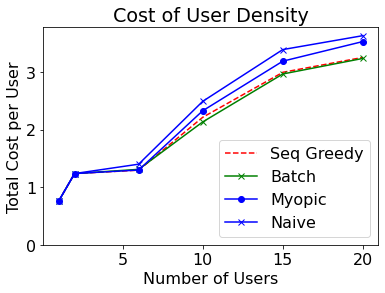

In [45]:
# Collect the correct costs
# Plot the plot
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 16}

matplotlib.rc('font', **font)
#figure(num=None, figsize=(5.5, 2.5), dpi=80, facecolor='w', edgecolor='k')
figure()
x_ax = [1,2,6,10,15,20]

plt.plot(x_ax, total_costs_SG, 'r--', label = 'Seq Greedy')
plt.plot(x_ax, total_costs_Batch, 'g-x', label = 'Batch')
plt.plot(x_ax, total_costs_Myopic, 'b-o', label = 'Myopic')
plt.plot(x_ax, total_costs_Naive, 'b-x', label = 'Naive')
# plt.plot(x_ax, total_costs_Cloud, 'r-x', label = 'Cloud')

# plt.xticks(x_ax)
# plt.xscale('log')
plt.legend()
plt.ylim(0,)


plt.title('Cost of User Density')
plt.xlabel('Number of Users')
plt.ylabel('Total Cost per User')

Text(0, 0.5, 'Latency Cost per User')

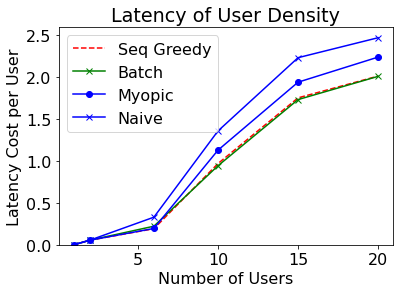

In [49]:
# Collect the correct costs
# Plot the plot
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 16}

matplotlib.rc('font', **font)
#figure(num=None, figsize=(5.5, 2.5), dpi=80, facecolor='w', edgecolor='k')
figure()
x_ax = [1,2,6,10,15,20]

plt.plot(x_ax, latencies_SG, 'r--', label = 'Seq Greedy')
plt.plot(x_ax, latencies_Batch, 'g-x', label = 'Batch')
plt.plot(x_ax, latencies_Myopic, 'b-o', label = 'Myopic')
plt.plot(x_ax, latencies_Naive, 'b-x', label = 'Naive')
# plt.plot(x_ax, total_costs_Cloud, 'r-x', label = 'Cloud')

# plt.xticks(x_ax)
# plt.xscale('log')
plt.legend()
plt.ylim(0,)


plt.title('Latency of User Density')
plt.xlabel('Number of Users')
plt.ylabel('Latency Cost per User')